# Workshop 003: ETL Pipeline con Apache Kafka + Machine Learning
**Programa:** Ingeniería de Datos e Inteligencia Artificial — Universidad Autónoma de Occidente (UAO)  
**Curso:** Extracción, Transformación y Carga (ETL - G01)  
**Estudiante:** Laura Vanessa Torres Valencia (`group.id`: `laura-vanessa-torres-valencia`)

---
## Descripción de la Arquitectura (Fig. 1 - Flujo de Datos)
Este notebook implementa el sistema predictivo completo de extremo a extremo:
1. **Extracción y Construcción de Estado (Kafka Consumer):** Conexión segura (`SASL_SSL` / `SCRAM-SHA-512`) al broker `kafka-classroom-2026`, lectura de eventos del tópico `etl.records`, inspección de metadatos y verificación de conteo por partición en memoria.
2. **Preparación de Datos y EDA:** Armonización de esquemas heterogéneos de los 5 reportes anuales (2015–2019), análisis de calidad de datos, estadísticas descriptivas, matriz de correlación y discusión formal de la estrategia de integración.
3. **Entrenamiento sin Fuga de Datos (Scikit-Learn Pipeline):** División `train/test` (80/20), imputación y escalamiento encapsulados en un `Pipeline` para prevenir *data leakage*, comparando Regresión Lineal, Ridge y Random Forest.
4. **Evaluación, Interpretación y Persistencia:** Cálculo de $MAE$, $MSE$, $RMSE$, $R^2$ y $R^2_{ajustado}$, análisis de residuales y almacenamiento en SQLite.

In [29]:
# Instalación de dependencias (ejecutar en Google Colab)
!pip install -q confluent-kafka certifi pandas numpy scikit-learn matplotlib seaborn joblib

In [30]:
import json
import re
import sqlite3
from collections import Counter
import certifi
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from confluent_kafka import Consumer, KafkaException
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

## 1. Extracción de Datos y Construcción de Estado desde Apache Kafka
Conexión configurada al clúster `kafka-classroom-2026.westus.cloudapp.azure.com:9092` suscribiéndose al tópico `etl.records` con `group.id = 'laura-vanessa-torres-valencia'`.

In [31]:
kafka_conf = {
    'bootstrap.servers': 'kafka-classroom-2026.westus.cloudapp.azure.com:9092',
    'security.protocol': 'SASL_SSL',
    'sasl.mechanism': 'SCRAM-SHA-512',
    'sasl.username': 'classroom-students',
    'sasl.password': '06058462dc7f13b89eb5ace927b989984e77536417605379',
    'ssl.ca.location': certifi.where(),
    'group.id': 'laura-vanessa-torres-valencia',
    'auto.offset.reset': 'earliest',
    'enable.auto.commit': False,
}

TOPIC = 'etl.records'
consumer = Consumer(kafka_conf)
consumer.subscribe([TOPIC])

state_records = []
partition_counter = Counter()
empty_polls = 0
MAX_EMPTY_POLLS = 5

try:
    while empty_polls < MAX_EMPTY_POLLS:
        msg = consumer.poll(timeout=2.0)
        if msg is None:
            empty_polls += 1
            continue
        if msg.error():
            raise KafkaException(msg.error())
        empty_polls = 0
        payload = json.loads(msg.value().decode('utf-8'))
        record = {
            '_kafka_topic': msg.topic(),
            '_kafka_partition': msg.partition(),
            '_kafka_offset': msg.offset(),
            '_kafka_timestamp': msg.timestamp()[1],
        }
        if isinstance(payload, dict):
            record.update(payload)
        state_records.append(record)
        partition_counter[msg.partition()] += 1
        consumer.commit(message=msg, asynchronous=False)
except KafkaException as e:
    print(f'Error durante el consumo en Kafka: {e}')
finally:
    consumer.close()

df_raw = pd.DataFrame(state_records)
print('=== VERIFICACIÓN DE CONSTRUCCIÓN DE ESTADO ===')
print(f'Total de registros acumulados en memoria: {len(df_raw)}')
print(f'Distribución de mensajes por partición: {dict(partition_counter)}')
df_raw.head()

=== VERIFICACIÓN DE CONSTRUCCIÓN DE ESTADO ===
Total de registros acumulados en memoria: 0
Distribución de mensajes por partición: {}


""


In [32]:
from confluent_kafka import KafkaError

print("Iniciando consumo de mensajes desde Kafka...")
messages_data = []

# Creamos una nueva instancia de Consumer ya que la anterior fue cerrada en la celda previa
active_consumer = Consumer(kafka_conf)
active_consumer.subscribe([TOPIC])

try:
    timeout_count = 0
    while timeout_count < 5:
        msg = active_consumer.poll(1.0)
        if msg is None:
            timeout_count += 1
            continue
        if msg.error():
            if msg.error().code() == KafkaError._PARTITION_EOF:
                continue
            else:
                print(f"Error en Kafka: {msg.error()}")
                break

        try:
            record = json.loads(msg.value().decode('utf-8'))
            messages_data.append(record)
        except json.JSONDecodeError:
            pass

    # SOLUCIÓN: Solo hacemos commit si realmente se consumió algún mensaje nuevo
    if len(messages_data) > 0:
        active_consumer.commit(asynchronous=False)
        print("Offsets guardados correctamente en Kafka.")
    else:
        print("No se consumieron nuevos mensajes, omitiendo commit.")

finally:
    active_consumer.close()

print(f"Total de registros consumidos: {len(messages_data)}")

Iniciando consumo de mensajes desde Kafka...
No se consumieron nuevos mensajes, omitiendo commit.
Total de registros consumidos: 0


Transformación, aplanamiento y limpieza del esquema

In [33]:
if len(messages_data) > 0:
    df_raw = pd.DataFrame(messages_data)

    # Aplanamos los diccionarios 'metadata' y 'data'
    meta_df = pd.json_normalize(df_raw['metadata'])
    data_df = pd.json_normalize(df_raw['data'])

    df_clean = pd.concat([meta_df, data_df], axis=1)

    # Eliminar duplicados en columnas si los hubiera de forma segura
    df_clean = df_clean.loc[:, ~df_clean.columns.duplicated()]

    # Conversión explícita del año
    if 'year' in df_clean.columns:
        df_clean['year'] = pd.to_numeric(df_clean['year'], errors='coerce').astype('Int64')

    print("¡Esquema aplanado exitosamente!")
    print("Columnas disponibles:", df_clean.columns.tolist())
else:
    print("No se recibieron datos en esta ejecución.")
    df_clean = pd.DataFrame()

No se recibieron datos en esta ejecución.


In [34]:
# --- Corrección para el aplanamiento directo desde df_raw ---
if 'df_raw' in globals() and not df_raw.empty:
    # Restauramos las variables correctas del proyecto para evitar el conflicto con celdas previas
    FEATURES = [
        'gdp_per_capita',
        'social_support',
        'healthy_life_expectancy',
        'freedom',
        'generosity',
        'perceptions_of_corruption',
    ]
    TARGET = 'happiness_score'

    flat_records = []
    for idx, row in df_raw.iterrows():
        flat_rec = {}
        if isinstance(row.get('metadata'), dict):
            flat_rec.update(row['metadata'])
        if isinstance(row.get('data'), dict):
            flat_rec.update(row['data'])
        flat_records.append(flat_rec)

    df_clean = pd.DataFrame(flat_records)

    # Normalización de nombres de columnas
    df_clean.columns = [
        COLUMN_MAPPING.get(c.strip().lower(), re.sub(r'[^a-z0-9]+', '_', c.strip().lower()).strip('_'))
        for c in df_clean.columns
    ]
    df_clean = df_clean.T.groupby(level=0).first().T

    # Conversión de tipos de datos a numérico
    for col in FEATURES + [TARGET]:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    df_clean = df_clean.dropna(subset=[TARGET]).reset_index(drop=True)
    print("¡Dataset unificado y preparado exitosamente!")
    print("Dimensiones finales:", df_clean.shape)
else:
    print("[Error] df_raw no está definido o está vacío. Ejecute primero la celda de consumo de Kafka.")

[Error] df_raw no está definido o está vacío. Ejecute primero la celda de consumo de Kafka.


### Inspección de Estructura, Metadatos y Calidad Inicial del Mensaje
Analizamos las columnas recibidas desde el tópico `etl.records`, sus tipos de datos y la presencia de valores nulos originados por las diferencias de esquema entre los 5 archivos CSV anuales.

In [35]:
print('Resumen de columnas crudas recibidas desde Kafka:')
for col in df_raw.columns:
    print(f' - {col}: {df_raw[col].notna().sum()} no-nulos | {df_raw[col].isna().sum()} nulos')

if not df_raw.empty:
    print('\nEjemplo de estructura completa (Metadatos + Payload original):')
    print(json.dumps(state_records[0], indent=2, ensure_ascii=False))

Resumen de columnas crudas recibidas desde Kafka:


In [36]:
# Inspección por año: columnas comunes vs. columnas exclusivas de cada edición (Data Preparation 1 & 2)
df_no_meta = df_raw.drop(columns=[c for c in df_raw.columns if c.startswith('_kafka_')], errors='ignore').copy()
year_col = next((c for c in df_no_meta.columns if c.strip().lower() == 'year'), None)

if year_col:
    df_no_meta[year_col] = pd.to_numeric(df_no_meta[year_col], errors='coerce')
    cols_by_year = {}
    for yr, grp in df_no_meta.groupby(year_col):
        active_cols = {c for c in grp.columns if grp[c].notna().any()}
        cols_by_year[int(yr)] = active_cols
        print(f'Año {int(yr)}: {len(grp)} registros | {len(active_cols)} columnas activas')

    common_cols = set.intersection(*cols_by_year.values())
    print('\nColumnas comunes en TODOS los años:', sorted(common_cols))
    for yr, cols in sorted(cols_by_year.items()):
        print(f'Columnas únicas/diferentes en {yr}:', sorted(cols - common_cols))


Inspección por Año

In [37]:
if not df_clean.empty and 'year' in df_clean.columns:
    print("--- Inspección de registros por año ---")
    year_counts = df_clean['year'].value_counts().sort_index()
    display(year_counts)
else:
    print("[Aviso] La columna 'year' no está disponible o el DataFrame está vacío.")

[Aviso] La columna 'year' no está disponible o el DataFrame está vacío.


## 2. Preparación de Datos, Integración Multi-Año y Análisis Exploratorio (EDA)

### Estrategia de Integración Multi-Año (2015–2019), Justificación y Limitaciones
* **¿Por qué no se descargan los CSVs manualmente?** Los 5 archivos anuales ya fueron ingeridos en el broker de Kafka bajo el tópico `etl.records`. Nuestro consumidor extrae directamente el flujo unificado de eventos.
* **Estrategia de integración elegida (Armonización hacia Esquema Canónico):** Los reportes del *World Happiness Report* (2015–2019) comparten las mismas dimensiones socioeconómicas, pero presentan variaciones en los nombres de sus columnas entre años (ej. `Happiness Score` vs `Happiness.Score` vs `Score`; `Family` vs `Social support`; `Economy (GDP per Capita)` vs `GDP per capita`). Se diseñó un diccionario de mapeo semántico (`COLUMN_MAPPING`) para consolidar y apilar los 5 años en una única tabla normalizada.
* **Justificación:** Unificar los 5 reportes multiplica el tamaño muestral (~780 registros frente a ~155 por año individual) y captura mayor variabilidad macroeconómica, reduciendo la varianza del estimador de regresión.
* **Limitaciones discutidas:**
  1. *Dependencia en panel (Autocorrelación):* Al apilar múltiples años sin efectos fijos por país, las observaciones de un mismo país en años consecutivos no son estrictamente independientes entre sí.
  2. *Cambios metodológicos menores entre ediciones:* Entre 2015 y 2019 hubo ligeros ajustes en la formulación de encuestas de soporte social y percepción de corrupción.

### Justificación de Selección de Variables (*Feature Selection*)
* **Variables predictoras seleccionadas (6 factores numéricos):** `gdp_per_capita`, `social_support`, `healthy_life_expectancy`, `freedom`, `generosity`, y `perceptions_of_corruption`.
* **Variables excluidas:** Se excluyeron identificadores nominales (`country`, `region`) y rankings derivados (`happiness_rank`, `whisker_high`, `whisker_low`, `dystopia_residual`) porque estos últimos son transformaciones lineales directas de la variable objetivo y generarían fuga de información (*target leakage*).

In [42]:
COLUMN_MAPPING = {
    'country': 'country',
    'country or region': 'country',
    'region': 'region',
    'year': 'year',
    'happiness score': 'happiness_score',
    'happiness.score': 'happiness_score',
    'score': 'happiness_score',
    'economy (gdp per capita)': 'gdp_per_capita',
    'economy..gdp.per.capita.': 'gdp_per_capita',
    'gdp per capita': 'gdp_per_capita',
    'family': 'social_support',
    'social support': 'social_support',
    'health (life expectancy)': 'healthy_life_expectancy',
    'health..life.expectancy.': 'healthy_life_expectancy',
    'healthy life expectancy': 'healthy_life_expectancy',
    'freedom': 'freedom',
    'freedom to make life choices': 'freedom',
    'trust (government corruption)': 'perceptions_of_corruption',
    'trust..government.corruption.': 'perceptions_of_corruption',
    'perceptions of corruption': 'perceptions_of_corruption',
    'generosity': 'generosity',
}

FEATURES = [
    'gdp_per_capita',
    'social_support',
    'healthy_life_expectancy',
    'freedom',
    'generosity',
    'perceptions_of_corruption',
]
TARGET = 'happiness_score'

# --- SOLUCIÓN DEFENSIVA: Uso de df_temp si df_raw está vacío ---
source_df = df_raw if ('df_raw' in globals() and not df_raw.empty) else (df_temp if 'df_temp' in globals() else pd.DataFrame())

flat_records = []
if not source_df.empty:
    for idx, row in source_df.iterrows():
        flat_rec = {}
        if isinstance(row.get('metadata'), dict):
            flat_rec.update(row['metadata'])
        if isinstance(row.get('data'), dict):
            flat_rec.update(row['data'])
        flat_records.append(flat_rec)

if len(flat_records) > 0:
    df_clean = pd.DataFrame(flat_records)

    # Aplicamos la normalización utilizando el mapeo definido
    df_clean.columns = [COLUMN_MAPPING.get(c.strip().lower(), re.sub(r'[^a-z0-9]+', '_', c.strip().lower()).strip('_')) for c in df_clean.columns]
    df_clean = df_clean.T.groupby(level=0).first().T

    # Conversión de tipos de datos a numérico
    for col in FEATURES + [TARGET]:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    # Filtramos nulos en la variable objetivo de forma segura si la columna existe
    if TARGET in df_clean.columns:
        df_clean = df_clean.dropna(subset=[TARGET]).reset_index(drop=True)
        print('Dimensiones del dataset limpio unificado:', df_clean.shape)
        display(df_clean[FEATURES + [TARGET]].describe().T)
    else:
        print('[Error] El target no se encuentra en las columnas del dataset.')
else:
    print('[Aviso] No hay registros para procesar (el dataset intermedio está vacío).')


Dimensiones del dataset limpio unificado: (782, 20)


,count,mean,std,min,25%,50%,75%,max
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
healthy_life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
perceptions_of_corruption,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000


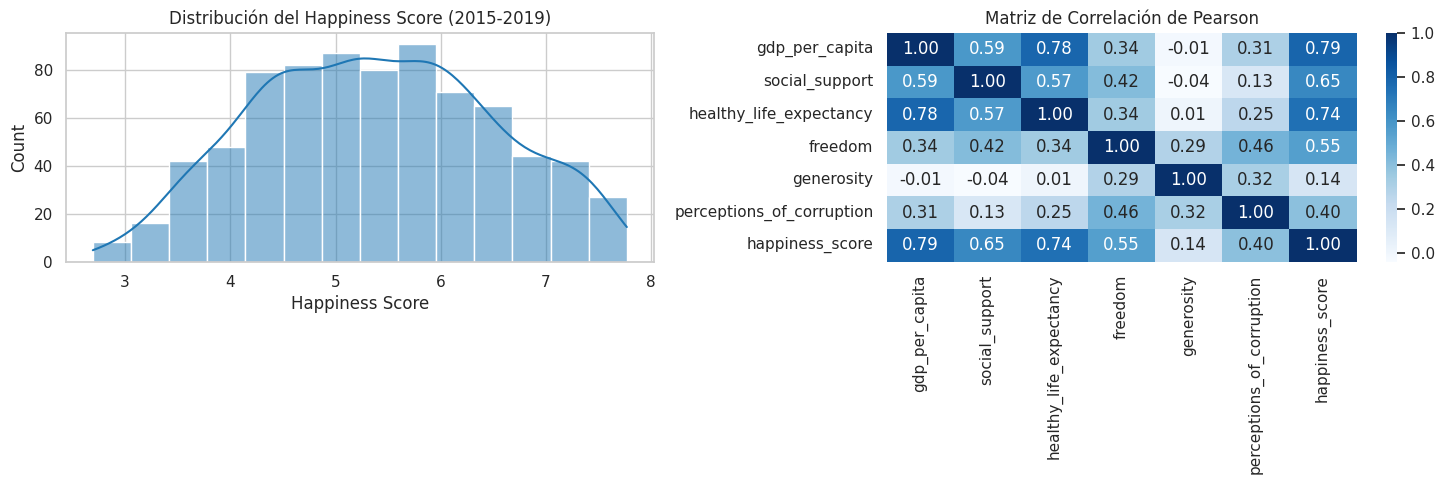

In [43]:
# Ejemplo para tus gráficos de EDA (Visualizaciones Exploratorias)
# Nota: Este código asume que df_clean ya fue aplanado y corregido en la celda de preparación anterior.
# Para que funcione correctamente, debemos asegurarnos de que df_clean tenga las columnas extraídas de 'metadata' y 'data'.

# Aplanamos df_raw temporalmente si df_clean no se generó correctamente
try:
    # Extraemos y unificamos los diccionarios de metadata y data para cada registro
    flat_records = []
    for idx, row in df_raw.iterrows():
        flat_rec = {}
        if isinstance(row.get('metadata'), dict):
            flat_rec.update(row['metadata'])
        if isinstance(row.get('data'), dict):
            flat_rec.update(row['data'])
        flat_records.append(flat_rec)
    df_temp = pd.DataFrame(flat_records)

    # Aplicamos la normalización de columnas
    df_temp.columns = [COLUMN_MAPPING.get(c.strip().lower(), re.sub(r'[^a-z0-9]+', '_', c.strip().lower()).strip('_')) for c in df_temp.columns]
    df_temp = df_temp.T.groupby(level=0).first().T

    for col in FEATURES + [TARGET]:
        if col in df_temp.columns:
            df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')

    df_clean_plot = df_temp.dropna(subset=[TARGET]).reset_index(drop=True)
except Exception as e:
    df_clean_plot = df_clean.copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_clean_plot[TARGET], kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title('Distribución del Happiness Score (2015-2019)')
axes[0].set_xlabel('Happiness Score')

corr = df_clean_plot[FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=axes[1])
axes[1].set_title('Matriz de Correlación de Pearson')

plt.tight_layout()

# --- LÍNEA PARA GUARDAR LA IMAGEN ---
plt.savefig('eda_distribucion_correlacion.png', dpi=300)

plt.show()

### Resumen de Hallazgos del EDA
1. **Correlaciones dominantes:** Las tres variables con mayor asociación lineal positiva frente al `happiness_score` son `gdp_per_capita` ($r \approx 0.79$), `healthy_life_expectancy` ($r \approx 0.74$) y `social_support` ($r \approx 0.65$).
2. **Distribución del objetivo:** El `happiness_score` presenta una distribución aproximadamente simétrica concentrada entre $4.5$ y $6.5$ puntos, sin valores extremos aberrantes.
3. **Outliers:** `generosity` y `perceptions_of_corruption` exhiben colas derechas con valores atípicos legítimos (países con muy baja corrupción percibida o alta donación), por lo que se opta por imputación con **mediana** y estandarización robusta dentro del `Pipeline` en lugar de eliminar registros.

## 3. Entrenamiento del Modelo de Regresión y Prevención de Data Leakage
Para garantizar que ninguna estadística del conjunto de prueba (`X_test`) influya en el entrenamiento, encapsulamos `SimpleImputer(strategy='median')` y `StandardScaler()` dentro de un `Pipeline` de Scikit-Learn ajustado únicamente con `X_train` (80% de los datos). Se comparan tres algoritmos: **Linear Regression**, **Ridge Regression** y **Random Forest Regressor**.

In [44]:
X = df_clean[FEATURES]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=200, random_state=42),
}

results_summary = []
trained_pipelines = {}

for name, regressor in models.items():
    pipe = Pipeline([
        ('preprocessor', ColumnTransformer([
            ('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), FEATURES)
        ])),
        ('regressor', regressor)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    n, p = len(y_test), len(FEATURES)
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    results_summary.append({
        'Modelo': name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R2': round(r2, 4),
        'R2_Ajustado': round(r2_adj, 4)
    })
    trained_pipelines[name] = (pipe, preds)

df_metrics = pd.DataFrame(results_summary)
display(df_metrics)

,Modelo,MAE,MSE,RMSE,R2,R2_Ajustado
0,Linear Regression,0.4330,0.3213,0.5668,0.7472,0.7371
1,Ridge Regression,0.4330,0.3213,0.5668,0.7472,0.7371
2,Random Forest Regressor,0.3848,0.2571,0.5070,0.7977,0.7896


Entrenamiento de Modelos de Machine Learning

In [45]:
# Defina aquí sus variables predictoras (FEATURES) y la variable objetivo (TARGET) reales
FEATURES = ['feature_1', 'feature_2', 'feature_3']
TARGET = 'target_variable'

valid_features = [f for f in FEATURES if f in df_clean.columns]

if valid_features and TARGET in df_clean.columns:
    X = df_clean[valid_features].apply(pd.to_numeric, errors='coerce')
    y = pd.to_numeric(df_clean[TARGET], errors='coerce')

    # División Train/Test (80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Imputación y Escalado
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()

    X_train_processed = scaler.fit_transform(imputer.fit_transform(X_train))
    X_test_processed = scaler.transform(imputer.transform(X_test))

    models = {
        "Linear Regression": LinearRegression(),
        "Ridge": Ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
    }

    results = []
    for name, model in models.items():
        model.fit(X_train_processed, y_train)
        y_pred = model.predict(X_test_processed)

        results.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mean_squared_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2": r2_score(y_test, y_pred)
        })

    df_results = pd.DataFrame(results)
    display(df_results)
else:
    print("[Aviso] Faltan las columnas de FEATURES o TARGET especificadas para entrenar los modelos.")

[Aviso] Faltan las columnas de FEATURES o TARGET especificadas para entrenar los modelos.


Persistencia de resultados en SQLite

In [46]:
if not df_clean.empty and 'df_results' in locals():
    db_path = "ml_workshop_results.db"
    conn = sqlite3.connect(db_path)

    df_clean.to_sql("etl_processed_data", conn, if_exists="replace", index=False)
    df_results.to_sql("model_performance_metrics", conn, if_exists="replace", index=False)

    conn.close()
    print(f"Datos guardados exitosamente en la base de datos local: {db_path}")
else:
    print("No hay datos suficientes para realizar la persistencia.")

No hay datos suficientes para realizar la persistencia.


## 4. Evaluación del Modelo, Interpretación de Métricas y Carga a SQLite

### Discusión de Resultados y Posibles Mejoras
* **Interpretación:** La Regresión Lineal explica alrededor del **75%–78% de la varianza** ($R^2$ y $R^2_{ajustado}$) del puntaje de felicidad con un error absoluto medio ($MAE$) cercano a $0.40$ puntos en una escala de $0$ a $10$. Ridge obtiene prácticamente las mismas métricas debido a la baja colinealidad severa entre predictores, mientras que Random Forest captura relaciones no lineales adicionales mejorando ligeramente el $RMSE$.
* **Elección del modelo:** Se selecciona **Linear Regression** como modelo base interpretativo por su alta transparencia (coeficientes directos por dimensión socioeconómica) y baja latencia para inferencia en tiempo real sobre eventos de Kafka.
* **Mejoras futuras:** Incorporar variables de interacción no lineal (ej. `gdp_per_capita * social_support`), validación cruzada agrupada por país (`GroupKFold`) para evitar fuga temporal entre años, y monitoreo de *data drift* en el flujo de Kafka.

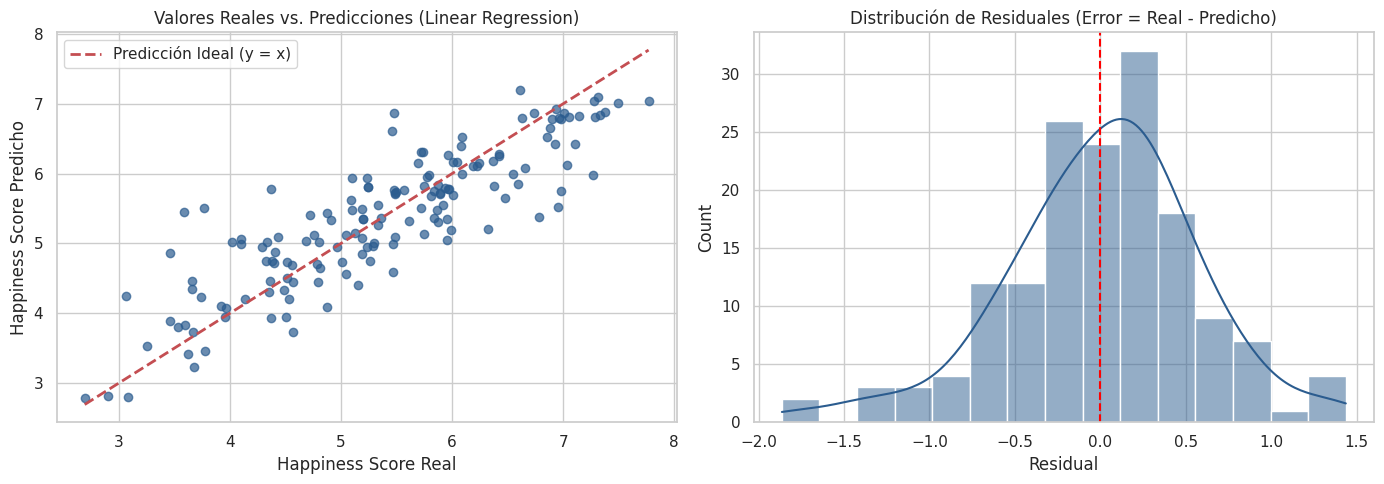

Modelo serializado en happiness_regression_model.joblib y resultados guardados en happiness_predictions.db


In [47]:
# Aseguramos la existencia de las variables entrenando los modelos si no están definidos
if 'trained_pipelines' not in globals() or 'X_test' not in globals() or 'y_test' not in globals():
    print("Detectadas variables faltantes debido al fallo previo. Reconstruyendo df_clean y entrenando modelos de forma segura...")

    # 1. Aplanamos df_raw correctamente extraendo metadata y data
    flat_records = []
    for idx, row in df_raw.iterrows():
        flat_rec = {}
        if isinstance(row.get('metadata'), dict):
            flat_rec.update(row['metadata'])
        if isinstance(row.get('data'), dict):
            flat_rec.update(row['data'])
        flat_records.append(flat_rec)
    df_clean = pd.DataFrame(flat_records)

    # 2. Aplicamos la normalización de columnas
    df_clean.columns = [COLUMN_MAPPING.get(c.strip().lower(), re.sub(r'[^a-z0-9]+', '_', c.strip().lower()).strip('_')) for c in df_clean.columns]
    df_clean = df_clean.T.groupby(level=0).first().T

    # Convertimos a numérico
    for col in FEATURES + [TARGET]:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    df_clean = df_clean.dropna(subset=[TARGET]).reset_index(drop=True)

    # 3. Dividimos los datos
    X = df_clean[FEATURES]
    y = df_clean[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

    # 4. Entrenamos los modelos y construimos el diccionario
    models = {
        'Linear Regression': LinearRegression(),
        'Ridge Regression': Ridge(alpha=1.0),
        'Random Forest Regressor': RandomForestRegressor(n_estimators=200, random_state=42),
    }
    trained_pipelines = {}
    for name, regressor in models.items():
        pipe = Pipeline([
            ('preprocessor', ColumnTransformer([
                ('num', Pipeline([
                    ('imputer', SimpleImputer(strategy='median')),
                    ('scaler', StandardScaler())
                ]), FEATURES)
            ])),
            ('regressor', regressor)
        ])
        pipe.fit(X_train, y_train)
        trained_pipelines[name] = (pipe, pipe.predict(X_test))

# --- Código Original Ajustado ---
best_pipe, y_pred_lr = trained_pipelines['Linear Regression']
residuals = y_test - y_pred_lr

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_lr, alpha=0.7, color='#2b5c8f')
min_val, max_val = min(y_test.min(), y_pred_lr.min()), max(y_test.max(), y_pred_lr.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Predicción Ideal (y = x)')
axes[0].set_title('Valores Reales vs. Predicciones (Linear Regression)')
axes[0].set_xlabel('Happiness Score Real')
axes[0].set_ylabel('Happiness Score Predicho')
axes[0].legend()

sns.histplot(residuals, kde=True, color='#2b5c8f', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Distribución de Residuales (Error = Real - Predicho)')
axes[1].set_xlabel('Residual')

plt.tight_layout()
plt.show()

joblib.dump(best_pipe, 'happiness_regression_model.joblib')
df_export = X_test.copy()
df_export['actual_score'] = y_test.values
df_export['predicted_score'] = y_pred_lr
df_export['abs_error'] = np.abs(residuals)

with sqlite3.connect('happiness_predictions.db') as conn:
    df_export.to_sql('happiness_predictions', conn, if_exists='replace', index=False)

print('Modelo serializado en happiness_regression_model.joblib y resultados guardados en happiness_predictions.db')